In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
bme_dir = '/projects/lindorff_group/people/thd711/HDXMS/code/'
sys.path.append(bme_dir)
from hdx_bme import HDXReweighterFast
from kint import *

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

proteins = ['Angiotensin', 'Bradykinin', 'Ab42', 'aSyn', 'Tau']
models = ['M9', 'M9DH', 'M9DH_scaled', 'M10', 'M10DH', 'M10DH_scaled', 'M11', 'M11DH', 'M11DH_scaled', 
          'M12', 'M12DH', 'M12DH_scaled', 'M14', 'M14DH', 'M14DH_scaled',  'kint']


In [2]:
ref_rates = 'Stofella2025'
if ref_rates == 'Stofella2025':
    file_ending = ''
elif ref_rates == 'Nguyen2018':
    file_ending = '_PDLA'
else:
    raise ValueError('Invalid reference rates')

master_df = pd.DataFrame()
model_rmse_prior = []
model_chi2r_prior = []
model_rmse_post = []
model_chi2r_post = []

model_rmse_prior_sd = []
model_chi2r_prior_sd = []
model_rmse_post_sd = []
model_chi2r_post_sd = []

for model in models:
    
    df = pd.DataFrame()
    prior_rmse_list = []
    prior_chi2r_list = []
    post_rmse_list = []
    post_chi2r_list = []

    for protein in proteins:
        # load data
        if model != 'kint':
            neff = np.loadtxt(f'../{protein}/rew{model}/phis{file_ending}.txt')
            rmse = np.loadtxt(f'../{protein}/rew{model}/rmse{file_ending}.txt')
            chi2r = np.loadtxt(f'../{protein}/rew{model}/chi2r{file_ending}.txt')
        else:
            rmse = np.loadtxt(f'../{protein}/{model}/rmse{file_ending}.txt')
            chi2r = np.loadtxt(f'../{protein}/{model}/chi2r{file_ending}.txt')

        # find last index where neff > 0.1
        if model != 'kint':
            opt_idx = np.where(neff > 0.1)[0][-1]
            rew_rmse = rmse[opt_idx]
            rew_chi2r = chi2r[opt_idx]
            prior_rmse = rmse[0]
            prior_chi2r = chi2r[0]
        else:
            opt_idx = 0
            rew_rmse = rmse
            rew_chi2r = chi2r
            prior_rmse = rmse
            prior_chi2r = chi2r

        # append data to dataframe
        prior_rmse_list.append(prior_rmse)
        prior_chi2r_list.append(prior_chi2r)
        post_rmse_list.append(rew_rmse)
        post_chi2r_list.append(rew_chi2r)

    model_rmse_prior.append(np.mean(prior_rmse_list))
    model_chi2r_prior.append(np.mean(prior_chi2r_list))
    model_rmse_post.append(np.mean(post_rmse_list))
    model_chi2r_post.append(np.mean(post_chi2r_list))

    model_rmse_prior_sd.append(np.std(prior_rmse_list))
    model_chi2r_prior_sd.append(np.std(prior_chi2r_list))
    model_rmse_post_sd.append(np.std(post_rmse_list))
    model_chi2r_post_sd.append(np.std(post_chi2r_list))

    df['Protein'] = proteins
    df['Rew. RMSE'] = post_rmse_list
    df['Rew. chi2r'] = post_chi2r_list
    df['Prior RMSE'] = prior_rmse_list
    df['Prior chi2r'] = prior_chi2r_list
    df.to_csv(f"stats_{model}{file_ending}.csv", index=False)

master_df['Model'] = models
master_df['Prior RMSE'] = model_rmse_prior
master_df['Prior chi2r'] = model_chi2r_prior
master_df['Rew. RMSE'] = model_rmse_post
master_df['Rew. chi2r'] = model_chi2r_post
master_df['Prior RMSE SD'] = model_rmse_prior_sd
master_df['Prior chi2r SD'] = model_chi2r_prior_sd
master_df['Rew. RMSE SD'] = model_rmse_post_sd
master_df['Rew. chi2r SD'] = model_chi2r_post_sd
master_df.to_csv(f"avg_model_stats{file_ending}.csv", index=False)

master_df


,Model,Prior RMSE,Prior chi2r,Rew. RMSE,Rew. chi2r,Prior RMSE SD,Prior chi2r SD,Rew. RMSE SD,Rew. chi2r SD
0,M9,0.142200,28.280203,0.085193,13.288838,0.034900,20.458042,0.041696,12.691243
1,M9DH,0.138872,29.529585,0.074466,12.524222,0.043278,19.519882,0.044095,12.976970
2,M9DH_scaled,0.139299,28.527169,0.077231,12.636007,0.034968,19.089174,0.040988,13.012129
3,M10,0.089119,13.268144,0.068329,7.915595,0.034333,13.504417,0.034837,8.043457
4,M10DH,0.058272,5.679287,0.028659,1.770876,0.024227,5.209509,0.013948,1.852050
5,M10DH_scaled,0.063884,6.612232,0.034413,2.727487,0.020573,6.555748,0.018663,3.299264
6,M11,0.088718,13.660625,0.065006,7.302869,0.037305,14.317776,0.033720,7.323755
7,M11DH,0.063473,7.159072,0.032014,2.330641,0.026030,6.717953,0.017461,2.389211
8,M11DH_scaled,0.067796,7.888132,0.036907,3.254766,0.022901,7.971188,0.021478,3.733926
9,M12,0.089064,13.678940,0.064977,7.290753,0.037228,14.269613,0.033677,7.293355


In [3]:
ref_rates = 'Nguyen2018'
if ref_rates == 'Stofella2025':
    file_ending = ''
elif ref_rates == 'Nguyen2018':
    file_ending = '_PDLA'
else:
    raise ValueError('Invalid reference rates')

master_df = pd.DataFrame()
model_rmse_prior = []
model_chi2r_prior = []
model_rmse_post = []
model_chi2r_post = []

model_rmse_prior_sd = []
model_chi2r_prior_sd = []
model_rmse_post_sd = []
model_chi2r_post_sd = []

for model in models:
    
    df = pd.DataFrame()
    prior_rmse_list = []
    prior_chi2r_list = []
    post_rmse_list = []
    post_chi2r_list = []

    for protein in proteins:
        # load data
        if model != 'kint':
            neff = np.loadtxt(f'../{protein}/rew{model}/phis{file_ending}.txt')
            rmse = np.loadtxt(f'../{protein}/rew{model}/rmse{file_ending}.txt')
            chi2r = np.loadtxt(f'../{protein}/rew{model}/chi2r{file_ending}.txt')
        else:
            rmse = np.loadtxt(f'../{protein}/{model}/rmse{file_ending}.txt')
            chi2r = np.loadtxt(f'../{protein}/{model}/chi2r{file_ending}.txt')

        # find last index where neff > 0.1
        if model != 'kint':
            opt_idx = np.where(neff > 0.1)[0][-1]
            rew_rmse = rmse[opt_idx]
            rew_chi2r = chi2r[opt_idx]
            prior_rmse = rmse[0]
            prior_chi2r = chi2r[0]
        else:
            opt_idx = 0
            rew_rmse = rmse
            rew_chi2r = chi2r
            prior_rmse = rmse
            prior_chi2r = chi2r

        # append data to dataframe
        prior_rmse_list.append(prior_rmse)
        prior_chi2r_list.append(prior_chi2r)
        post_rmse_list.append(rew_rmse)
        post_chi2r_list.append(rew_chi2r)

    model_rmse_prior.append(np.mean(prior_rmse_list))
    model_chi2r_prior.append(np.mean(prior_chi2r_list))
    model_rmse_post.append(np.mean(post_rmse_list))
    model_chi2r_post.append(np.mean(post_chi2r_list))

    model_rmse_prior_sd.append(np.std(prior_rmse_list))
    model_chi2r_prior_sd.append(np.std(prior_chi2r_list))
    model_rmse_post_sd.append(np.std(post_rmse_list))
    model_chi2r_post_sd.append(np.std(post_chi2r_list))

    df['Protein'] = proteins
    df['Rew. RMSE'] = post_rmse_list
    df['Rew. chi2r'] = post_chi2r_list
    df['Prior RMSE'] = prior_rmse_list
    df['Prior chi2r'] = prior_chi2r_list
    df.to_csv(f"stats_{model}{file_ending}.csv", index=False)

master_df['Model'] = models
master_df['Prior RMSE'] = model_rmse_prior
master_df['Prior chi2r'] = model_chi2r_prior
master_df['Rew. RMSE'] = model_rmse_post
master_df['Rew. chi2r'] = model_chi2r_post
master_df['Prior RMSE SD'] = model_rmse_prior_sd
master_df['Prior chi2r SD'] = model_chi2r_prior_sd
master_df['Rew. RMSE SD'] = model_rmse_post_sd
master_df['Rew. chi2r SD'] = model_chi2r_post_sd
master_df.to_csv(f"avg_model_stats{file_ending}.csv", index=False)

master_df


,Model,Prior RMSE,Prior chi2r,Rew. RMSE,Rew. chi2r,Prior RMSE SD,Prior chi2r SD,Rew. RMSE SD,Rew. chi2r SD
0,M9,0.202346,55.002369,0.145897,33.597771,0.031103,31.802654,0.045579,27.748040
1,M9DH,0.203067,61.047981,0.138109,35.522849,0.047689,36.655077,0.054683,30.063020
2,M9DH_scaled,0.203273,59.266455,0.142110,35.411004,0.038118,35.063205,0.047942,29.556522
3,M10,0.126535,22.117628,0.109781,16.860902,0.038654,16.361884,0.042271,12.802694
4,M10DH,0.113960,18.983341,0.067804,8.812244,0.030547,12.670029,0.032393,8.020772
5,M10DH_scaled,0.116765,19.189729,0.079280,10.301726,0.025207,12.992583,0.027909,8.937837
6,M11,0.132377,24.987623,0.107279,16.459363,0.037229,18.765336,0.041667,12.576116
7,M11DH,0.122847,23.199423,0.075615,11.901151,0.031559,16.151655,0.039848,11.576114
8,M11DH_scaled,0.125085,23.145479,0.082259,12.491847,0.025310,16.328940,0.032208,12.020975
9,M12,0.132845,25.073438,0.107293,16.467272,0.037290,18.711958,0.041674,12.576175


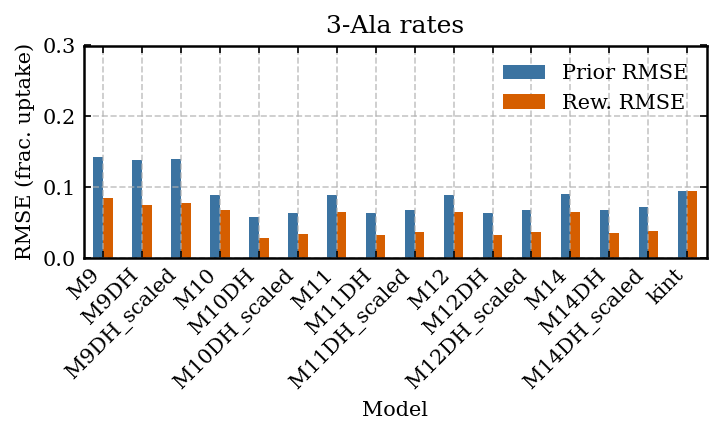

In [5]:
# plot the master df
master_df = pd.read_csv(f"avg_model_stats.csv")

master_df.plot(x='Model', y=['Prior RMSE', 'Rew. RMSE'], 
                color = ['#3B73A1', '#D55E00'], kind='bar', figsize=(5,3), legend=True)
plt.ylabel('RMSE (frac. uptake)')
plt.title('3-Ala rates')
plt.xticks(rotation=45, ha='right')
plt.ylim(0,0.3)
plt.tight_layout()
plt.savefig('avg_rmse_comparison.pdf')


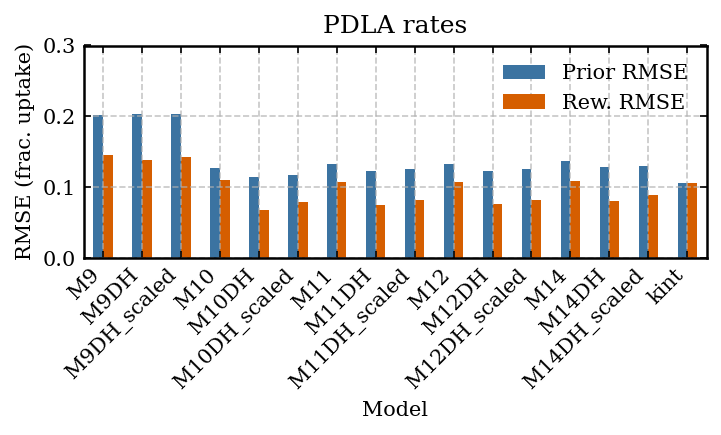

In [6]:
# plot the master df
master_df = pd.read_csv(f"avg_model_stats_PDLA.csv")

master_df.plot(x='Model', y=['Prior RMSE', 'Rew. RMSE'], 
                color = ['#3B73A1', '#D55E00'], kind='bar', figsize=(5,3), legend=True)
plt.ylabel('RMSE (frac. uptake)')
plt.title('PDLA rates')
plt.xticks(rotation=45, ha='right')
plt.ylim(0,0.3)
plt.tight_layout()
plt.savefig('avg_rmse_comparison_PDLA.pdf')


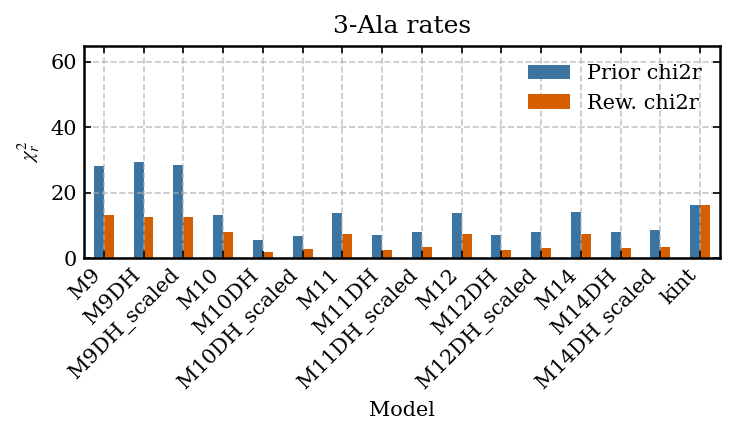

In [8]:
# plot the master df
master_df = pd.read_csv(f"avg_model_stats.csv")

master_df.plot(x='Model', y=['Prior chi2r', 'Rew. chi2r'], 
                color = ['#3B73A1', '#D55E00'], kind='bar', figsize=(5,3), legend=True)
plt.ylabel('$\chi^2_r$')
plt.title('3-Ala rates')
plt.xticks(rotation=45, ha='right')
plt.ylim(0,65)
plt.tight_layout()
plt.savefig('avg_chi2r_comparison.pdf')


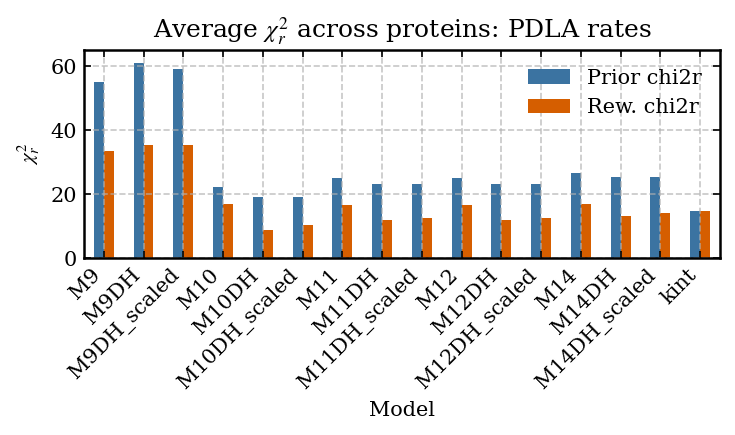

In [9]:
# plot the master df
master_df = pd.read_csv(f"avg_model_stats_PDLA.csv")

master_df.plot(x='Model', y=['Prior chi2r', 'Rew. chi2r'], 
                color = ['#3B73A1', '#D55E00'], kind='bar', figsize=(5,3), legend=True)
plt.ylabel('$\chi^2_r$')
plt.title('Average $\chi^2_r$ across proteins: PDLA rates')
plt.xticks(rotation=45, ha='right')
plt.ylim(0,65)
plt.tight_layout()
plt.savefig('avg_chi2r_comparison_PDLA.pdf')


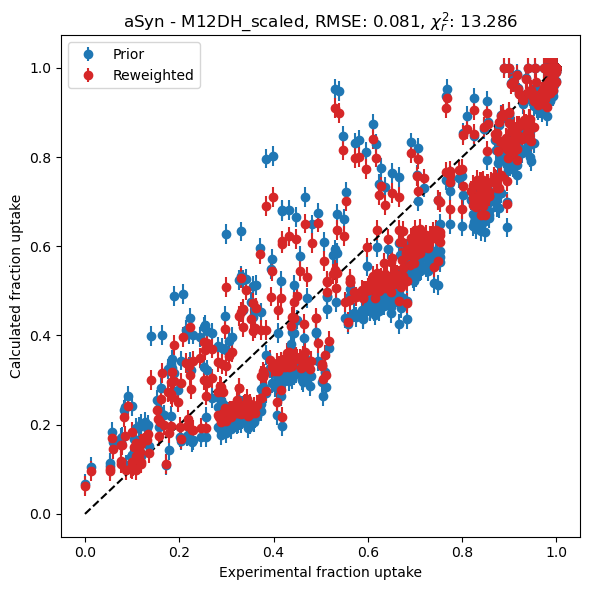

In [8]:
# show correlation of experimental and calculated fraction uptake values for the M10DH_scaled model
# and a given protein

model = 'M12DH_scaled'
protein = 'aSyn'

# get experimental data
df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

# reweighting stuff
neff = np.loadtxt(f'../{protein}/rew{model}/phis.txt')
rmse = np.loadtxt(f'../{protein}/rew{model}/rmse.txt')
chi2r = np.loadtxt(f'../{protein}/rew{model}/chi2r.txt')
opt_idx = np.where(neff > 0.2)[0][-1]
pred_uptake_prior = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[0]
pred_uptake_post = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[opt_idx]

# correlation plot
plt.figure(figsize=(6,6))
plt.errorbar(F_exp, pred_uptake_prior, yerr=sigma, fmt='o', color='tab:blue', label='Prior')
plt.errorbar(F_exp, pred_uptake_post, yerr=sigma, fmt='o', color='tab:red', label='Reweighted')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('Experimental fraction uptake')
plt.ylabel('Calculated fraction uptake')
plt.title(f'{protein} - {model}, RMSE: {rmse[opt_idx]:.3f}, $\chi^2_r$: {chi2r[opt_idx]:.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(f'{protein}_{model}_correlation.png')


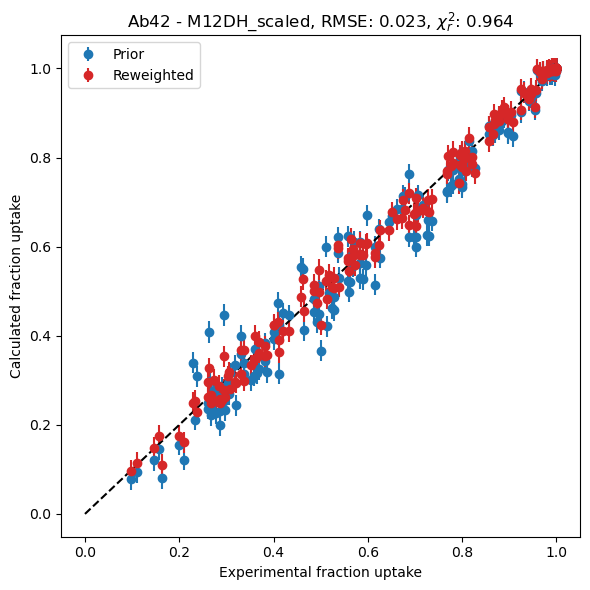

In [9]:
# show correlation of experimental and calculated fraction uptake values for the M10DH_scaled model
# and a given protein

model = 'M12DH_scaled'
protein = 'Ab42'

# get experimental data
df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

# reweighting stuff
neff = np.loadtxt(f'../{protein}/rew{model}/phis.txt')
rmse = np.loadtxt(f'../{protein}/rew{model}/rmse.txt')
chi2r = np.loadtxt(f'../{protein}/rew{model}/chi2r.txt')
opt_idx = np.where(neff > 0.2)[0][-1]
pred_uptake_prior = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[0]
pred_uptake_post = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[opt_idx]

# correlation plot
plt.figure(figsize=(6,6))
plt.errorbar(F_exp, pred_uptake_prior, yerr=sigma, fmt='o', color='tab:blue', label='Prior')
plt.errorbar(F_exp, pred_uptake_post, yerr=sigma, fmt='o', color='tab:red', label='Reweighted')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('Experimental fraction uptake')
plt.ylabel('Calculated fraction uptake')
plt.title(f'{protein} - {model}, RMSE: {rmse[opt_idx]:.3f}, $\chi^2_r$: {chi2r[opt_idx]:.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(f'{protein}_{model}_correlation.png')


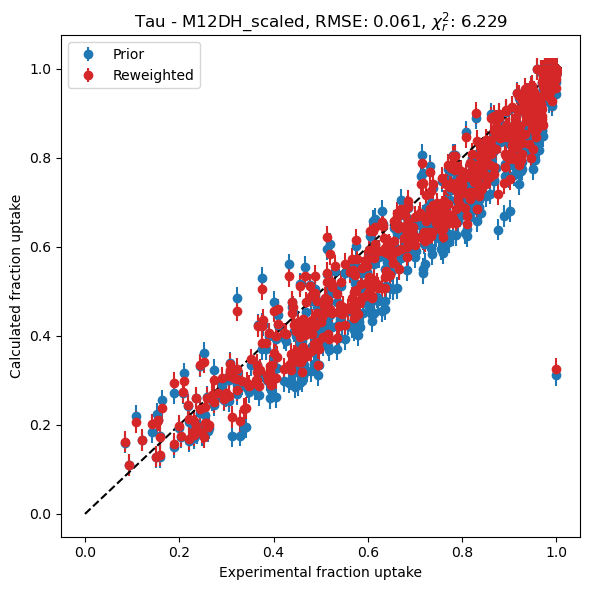

In [10]:
# show correlation of experimental and calculated fraction uptake values for the M10DH_scaled model
# and a given protein

model = 'M12DH_scaled'
protein = 'Tau'

# get experimental data
df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

# reweighting stuff
neff = np.loadtxt(f'../{protein}/rew{model}/phis.txt')
rmse = np.loadtxt(f'../{protein}/rew{model}/rmse.txt')
chi2r = np.loadtxt(f'../{protein}/rew{model}/chi2r.txt')
opt_idx = np.where(neff > 0.2)[0][-1]
pred_uptake_prior = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[0]
pred_uptake_post = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[opt_idx]

# correlation plot
plt.figure(figsize=(6,6))
plt.errorbar(F_exp, pred_uptake_prior, yerr=sigma, fmt='o', color='tab:blue', label='Prior')
plt.errorbar(F_exp, pred_uptake_post, yerr=sigma, fmt='o', color='tab:red', label='Reweighted')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('Experimental fraction uptake')
plt.ylabel('Calculated fraction uptake')
plt.title(f'{protein} - {model}, RMSE: {rmse[opt_idx]:.3f}, $\chi^2_r$: {chi2r[opt_idx]:.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(f'{protein}_{model}_correlation.png')


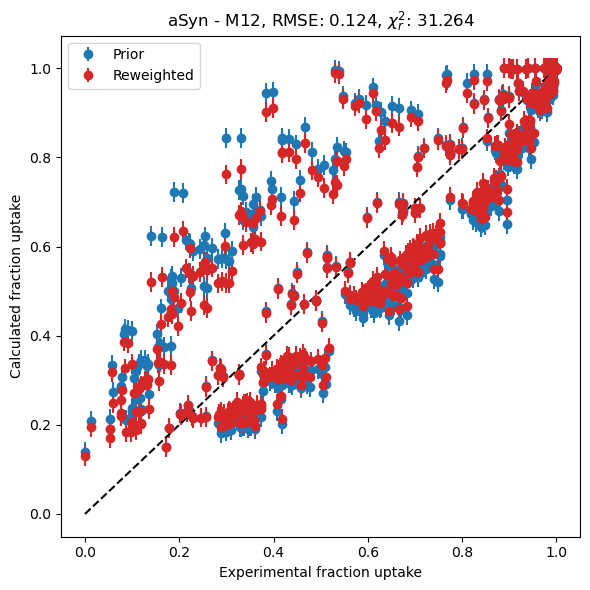

In [11]:
# show correlation of experimental and calculated fraction uptake values for the M10DH_scaled model
# and a given protein

model = 'M12'
protein = 'aSyn'

# get experimental data
df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

# reweighting stuff
neff = np.loadtxt(f'../{protein}/rew{model}/phis.txt')
rmse = np.loadtxt(f'../{protein}/rew{model}/rmse.txt')
chi2r = np.loadtxt(f'../{protein}/rew{model}/chi2r.txt')
opt_idx = np.where(neff > 0.2)[0][-1]
pred_uptake_prior = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[0]
pred_uptake_post = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[opt_idx]

# correlation plot
plt.figure(figsize=(6,6))
plt.errorbar(F_exp, pred_uptake_prior, yerr=sigma, fmt='o', color='tab:blue', label='Prior')
plt.errorbar(F_exp, pred_uptake_post, yerr=sigma, fmt='o', color='tab:red', label='Reweighted')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('Experimental fraction uptake')
plt.ylabel('Calculated fraction uptake')
plt.title(f'{protein} - {model}, RMSE: {rmse[opt_idx]:.3f}, $\chi^2_r$: {chi2r[opt_idx]:.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(f'{protein}_{model}_correlation.png')


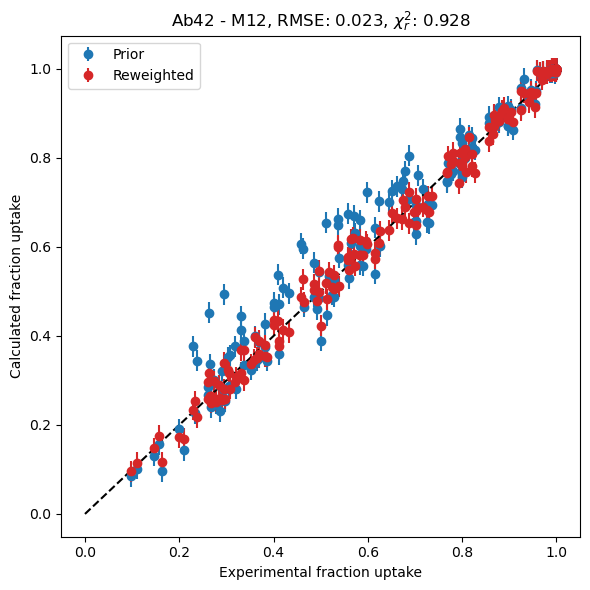

In [12]:
# show correlation of experimental and calculated fraction uptake values for the M10DH_scaled model
# and a given protein

model = 'M12'
protein = 'Ab42'

# get experimental data
df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

# reweighting stuff
neff = np.loadtxt(f'../{protein}/rew{model}/phis.txt')
rmse = np.loadtxt(f'../{protein}/rew{model}/rmse.txt')
chi2r = np.loadtxt(f'../{protein}/rew{model}/chi2r.txt')
opt_idx = np.where(neff > 0.2)[0][-1]
pred_uptake_prior = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[0]
pred_uptake_post = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[opt_idx]

# correlation plot
plt.figure(figsize=(6,6))
plt.errorbar(F_exp, pred_uptake_prior, yerr=sigma, fmt='o', color='tab:blue', label='Prior')
plt.errorbar(F_exp, pred_uptake_post, yerr=sigma, fmt='o', color='tab:red', label='Reweighted')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('Experimental fraction uptake')
plt.ylabel('Calculated fraction uptake')
plt.title(f'{protein} - {model}, RMSE: {rmse[opt_idx]:.3f}, $\chi^2_r$: {chi2r[opt_idx]:.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(f'{protein}_{model}_correlation.png')


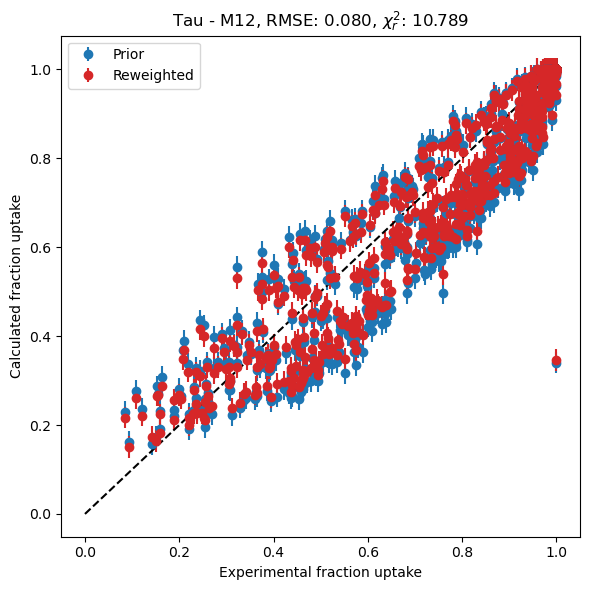

In [13]:
# show correlation of experimental and calculated fraction uptake values for the M10DH_scaled model
# and a given protein

model = 'M12'
protein = 'Tau'

# get experimental data
df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

# reweighting stuff
neff = np.loadtxt(f'../{protein}/rew{model}/phis.txt')
rmse = np.loadtxt(f'../{protein}/rew{model}/rmse.txt')
chi2r = np.loadtxt(f'../{protein}/rew{model}/chi2r.txt')
opt_idx = np.where(neff > 0.2)[0][-1]
pred_uptake_prior = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[0]
pred_uptake_post = np.load(f'../{protein}/rew{model}/pred_uptakes.npy')[opt_idx]

# correlation plot
plt.figure(figsize=(6,6))
plt.errorbar(F_exp, pred_uptake_prior, yerr=sigma, fmt='o', color='tab:blue', label='Prior')
plt.errorbar(F_exp, pred_uptake_post, yerr=sigma, fmt='o', color='tab:red', label='Reweighted')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('Experimental fraction uptake')
plt.ylabel('Calculated fraction uptake')
plt.title(f'{protein} - {model}, RMSE: {rmse[opt_idx]:.3f}, $\chi^2_r$: {chi2r[opt_idx]:.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(f'{protein}_{model}_correlation.png')


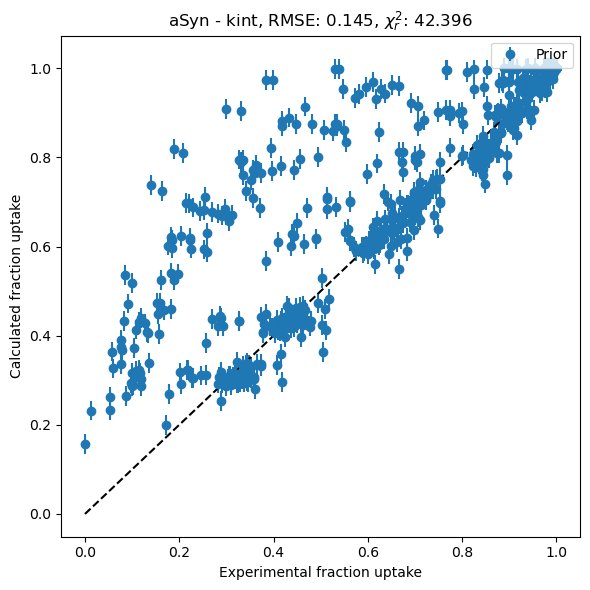

In [14]:
# show correlation of experimental and calculated fraction uptake values for the M10DH_scaled model
# and a given protein

model = 'kint'
protein = 'aSyn'

# get experimental data
df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

# reweighting stuff
rmse = np.loadtxt(f'../{protein}/{model}/rmse.txt')
chi2r = np.loadtxt(f'../{protein}/{model}/chi2r.txt')
pred_uptake_prior = np.load(f'../{protein}/{model}/pred_uptakes.npy')[0]


# correlation plot
plt.figure(figsize=(6,6))
plt.errorbar(F_exp, pred_uptake_prior, yerr=sigma, fmt='o', color='tab:blue', label='Prior')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('Experimental fraction uptake')
plt.ylabel('Calculated fraction uptake')
plt.title(f'{protein} - {model}, RMSE: {rmse:.3f}, $\chi^2_r$: {chi2r:.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(f'{protein}_{model}_correlation.png')


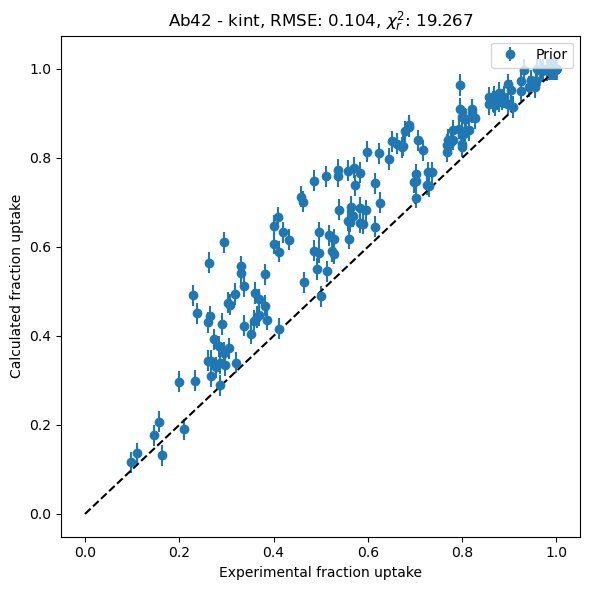

In [15]:
# show correlation of experimental and calculated fraction uptake values for the M10DH_scaled model
# and a given protein

model = 'kint'
protein = 'Ab42'

# get experimental data
df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

# reweighting stuff
rmse = np.loadtxt(f'../{protein}/{model}/rmse.txt')
chi2r = np.loadtxt(f'../{protein}/{model}/chi2r.txt')
pred_uptake_prior = np.load(f'../{protein}/{model}/pred_uptakes.npy')[0]


# correlation plot
plt.figure(figsize=(6,6))
plt.errorbar(F_exp, pred_uptake_prior, yerr=sigma, fmt='o', color='tab:blue', label='Prior')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('Experimental fraction uptake')
plt.ylabel('Calculated fraction uptake')
plt.title(f'{protein} - {model}, RMSE: {rmse:.3f}, $\chi^2_r$: {chi2r:.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(f'{protein}_{model}_correlation.png')


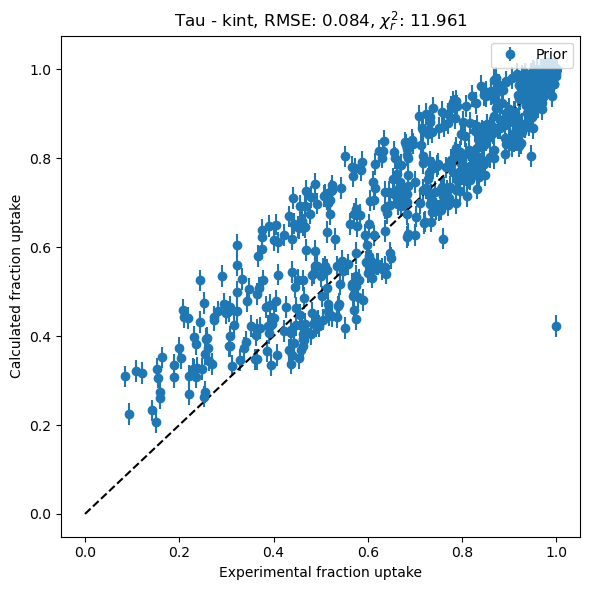

In [16]:
# show correlation of experimental and calculated fraction uptake values for the M10DH_scaled model
# and a given protein

model = 'kint'
protein = 'Tau'

# get experimental data
df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

# reweighting stuff
rmse = np.loadtxt(f'../{protein}/{model}/rmse.txt')
chi2r = np.loadtxt(f'../{protein}/{model}/chi2r.txt')
pred_uptake_prior = np.load(f'../{protein}/{model}/pred_uptakes.npy')[0]


# correlation plot
plt.figure(figsize=(6,6))
plt.errorbar(F_exp, pred_uptake_prior, yerr=sigma, fmt='o', color='tab:blue', label='Prior')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('Experimental fraction uptake')
plt.ylabel('Calculated fraction uptake')
plt.title(f'{protein} - {model}, RMSE: {rmse:.3f}, $\chi^2_r$: {chi2r:.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(f'{protein}_{model}_correlation.png')
